## <span style="color:#1F4E79;">__Parameter Recovery in the Bradley-Terry Model__</span>
__*This notebook studies how accurately the true parameters can be recovered from simulated comparison data.*__

In [24]:
# Import the libraries and reusable Bradley–Terry functions required in this notebook.
# Also to set a fixed random seed and consistent display settings for reproducible experiments.
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bradley_terry import *
SEED=20260831
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision",4)

##### Reusable Bradley–Terry Functions

| Function | Purpose |
|---|---|
| `center_parameters()` | Shifts parameters so their mean is zero. |
| `generate_uniform_comparison_data()` | Samples every possible pair uniformly and returns `(winner, loser)` observations. |
| `generate_comparison_data_from_edges()` | Generates observations using only the edges of a specified comparison graph. |
| `estimate_parameters_with_gradient_descent()` | Estimates parameters by minimizing the NLL. |
| `parameter_recovery_error()` | Calculates RMSE between true and estimated parameters. |
| `run_parameter_recovery_trials()` | Repeats an experiment across independent random datasets. |

In [30]:
# Define directories for saving thesis figures and experiment tables.

from pathlib import Path

current_directory = Path.cwd().resolve()

repository_root = next(
    path
    for path in [current_directory, *current_directory.parents]
    if (path / ".git").exists()
)

figure_directory = (
    repository_root
    / "docs"
    / "thesis"
    / "images"
    / "experiments"
    / "bradley_terry"
)

table_directory = (
    repository_root
    / "results"
    / "tables"
    / "bradley_terry"
)

figure_directory.mkdir(
    parents=True,
    exist_ok=True,
)

table_directory.mkdir(
    parents=True,
    exist_ok=True,
)

print("Figures will be saved in:")
print(figure_directory)

print("\nTables will be saved in:")
print(table_directory)

Figures will be saved in:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry

Tables will be saved in:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry


In [6]:
# Define a fixed set of 10 centred true parameters for the baseline experiment.
number_of_items=10
true_parameters=np.linspace(
    -1.5,
    1.5,
    number_of_items
)
true_parameters=center_parameters(
    true_parameters
)
true_parameter_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "true_parameter":true_parameters
})
true_parameter_table

,item,true_parameter
0,0,-1.5000
1,1,-1.1667
2,2,-0.8333
3,3,-0.5000
4,4,-0.1667
5,5,0.1667
6,6,0.5000
7,7,0.8333
8,8,1.1667
9,9,1.5000


In [7]:
# Generate a reproducible baseline dataset of paired winner–loser observations.
number_of_comparisons=1000
rng=np.random.default_rng(SEED)
comparisons=generate_uniform_comparison_data(
    true_parameters,
    number_of_comparisons,
    rng
)
comparison_table=pd.DataFrame(
    comparisons,
    columns=["winner","loser"]
)
comparison_table.head(10)

,winner,loser
0,8,1
1,8,0
2,3,5
3,3,8
4,1,3
5,8,6
6,9,2
7,9,5
8,9,1
9,8,2


In [8]:
# (Basic EDA) Summarise the wins, appearances and observed win rate of every item.

comparison_array=np.asarray(
    comparisons,
    dtype=int
)

wins=np.bincount(
    comparison_array[:,0],
    minlength=number_of_items
)

appearances=np.bincount(
    comparison_array.flatten(),
    minlength=number_of_items
)

observed_win_rate=wins/appearances

comparison_summary_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "wins":wins,
    "appearances":appearances,
    "observed_win_rate":observed_win_rate,
    "true_parameter":true_parameters
})

comparison_summary_table

,item,wins,appearances,observed_win_rate,true_parameter
0,0,40,187,0.2139,-1.5000
1,1,42,179,0.2346,-1.1667
2,2,76,219,0.3470,-0.8333
3,3,76,190,0.4000,-0.5000
4,4,92,217,0.4240,-0.1667
5,5,104,197,0.5279,0.1667
6,6,115,201,0.5721,0.5000
7,7,142,207,0.6860,0.8333
8,8,150,205,0.7317,1.1667
9,9,163,198,0.8232,1.5000


In [9]:
# Estimate the unknown parameters and record the optimization time and NLL history.

learning_rate=0.1
maximum_iterations=1000

start_time=perf_counter()

estimated_parameters,nll_history=(
    estimate_parameters_with_gradient_descent(
        number_of_items=number_of_items,
        comparisons=comparisons,
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )
)

estimation_time=perf_counter()-start_time

print(f"Initial average NLL: {nll_history[0]:.4f}")
print(f"Final average NLL:   {nll_history[-1]:.4f}")
print(f"Estimation time:     {estimation_time:.4f} seconds")

Initial average NLL: 0.6931
Final average NLL:   0.5333
Estimation time:     0.3775 seconds


In [10]:
# Compare the true and estimated parameters and calculate the baseline recovery error.

recovery_error=parameter_recovery_error(
    true_parameters,
    estimated_parameters
)

parameter_comparison_table=pd.DataFrame({
    "item":np.arange(number_of_items),
    "true_parameter":true_parameters,
    "estimated_parameter":estimated_parameters,
    "estimation_error":(
        estimated_parameters-true_parameters
    )
})

display(parameter_comparison_table)

print(f"Parameter-recovery RMSE: {recovery_error:.4f}")

,item,true_parameter,estimated_parameter,estimation_error
0,0,-1.5000,-1.3480,0.1520
1,1,-1.1667,-1.1493,0.0174
2,2,-0.8333,-0.6355,0.1979
3,3,-0.5000,-0.4285,0.0715
4,4,-0.1667,-0.3166,-0.1499
5,5,0.1667,0.1116,-0.0550
6,6,0.5000,0.3535,-0.1465
7,7,0.8333,0.8761,0.0428
8,8,1.1667,0.9898,-0.1769
9,9,1.5000,1.5469,0.0469


Parameter-recovery RMSE: 0.1224


#### Experiment 1: Effect of the Number of Comparisons
Here,the experiment studies how the amount of observed comparison data affects parameter recovery.
The number of items, true parameters, sampling method and optimization settings are kept fixed. Only the number of pairwise comparisons is changed.

In [25]:
# Reset the fixed parameters used in Experiment 1.

number_of_items = 10

true_parameters = center_parameters(
    np.linspace(
        -1.5,
        1.5,
        number_of_items,
    )
)

print("Number of parameters:", len(true_parameters))

Number of parameters: 10


In [32]:
# Recompute the complete baseline experiment with 10 items.

number_of_items = 10
number_of_comparisons = 1000

true_parameters = center_parameters(
    np.linspace(
        -1.5,
        1.5,
        number_of_items,
    )
)

rng = np.random.default_rng(SEED)

comparisons = generate_uniform_comparison_data(
    true_parameters,
    number_of_comparisons,
    rng,
)

estimated_parameters, nll_history = (
    estimate_parameters_with_gradient_descent(
        number_of_items=number_of_items,
        comparisons=comparisons,
        learning_rate=0.1,
        maximum_iterations=1000,
    )
)

recovery_error = parameter_recovery_error(
    true_parameters,
    estimated_parameters,
)

print("True parameters shape:", true_parameters.shape)
print("Estimated parameters shape:", estimated_parameters.shape)
print(f"Recovery RMSE: {recovery_error:.4f}")

True parameters shape: (10,)
Estimated parameters shape: (10,)
Recovery RMSE: 0.1224


Figure saved to:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/baseline_parameter_recovery.pdf


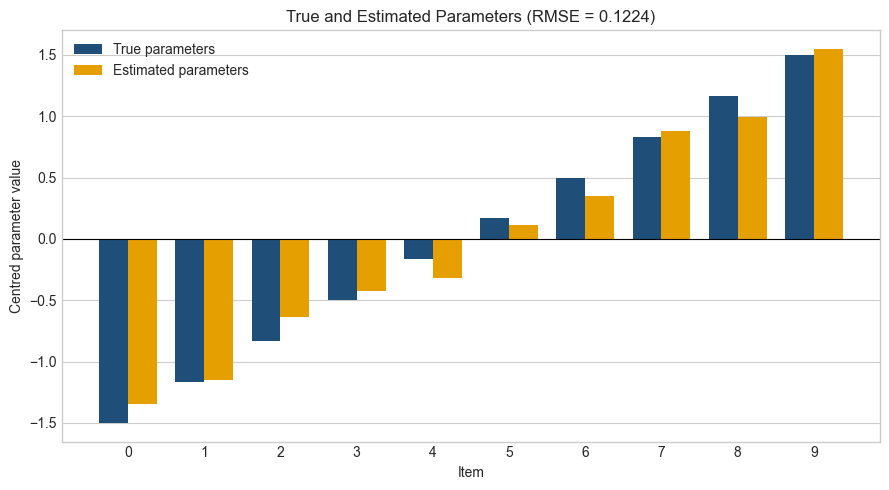

In [33]:
# Plot the true and estimated parameters for each item.
item_indices=np.arange(number_of_items)
bar_width=0.38

fig,ax=plt.subplots(
    figsize=(9,5)
)

ax.bar(
    item_indices-bar_width/2,
    true_parameters,
    width=bar_width,
    label="True parameters",
    color="#1F4E79"
)

ax.bar(
    item_indices+bar_width/2,
    estimated_parameters,
    width=bar_width,
    label="Estimated parameters",
    color="#E69F00"
)

ax.axhline(
    0,
    color="black",
    linewidth=0.8
)
ax.set_xlabel("Item")
ax.set_ylabel("Centred parameter value")
ax.set_title(
    f"True and Estimated Parameters (RMSE = {recovery_error:.4f})"
)
ax.set_xticks(item_indices)
ax.legend()
ax.grid(axis="x",visible=False)
plt.tight_layout()

baseline_figure_path = (
    figure_directory
    / "baseline_parameter_recovery.pdf"
)

fig.savefig(
    baseline_figure_path,
    bbox_inches="tight",
)

print("Figure saved to:")
print(baseline_figure_path)

plt.show()

In [34]:
# Record and save the verified baseline results.

parameter_comparison_table = pd.DataFrame({
    "item": np.arange(number_of_items),
    "true_parameter": true_parameters,
    "estimated_parameter": estimated_parameters,
    "estimation_error": (
        estimated_parameters - true_parameters
    ),
})

print(f"Number of items:       {number_of_items}")
print(f"Number of comparisons: {number_of_comparisons}")
print(f"Initial average NLL:   {nll_history[0]:.4f}")
print(f"Final average NLL:     {nll_history[-1]:.4f}")
print(f"Recovery RMSE:         {recovery_error:.4f}")

display(parameter_comparison_table)

baseline_table_path = (
    table_directory
    / "baseline_parameter_recovery.csv"
)

parameter_comparison_table.to_csv(
    baseline_table_path,
    index=False,
)

print("\nTable saved to:")
print(baseline_table_path)

Number of items:       10
Number of comparisons: 1000
Initial average NLL:   0.6931
Final average NLL:     0.5333
Recovery RMSE:         0.1224


,item,true_parameter,estimated_parameter,estimation_error
0,0,-1.5000,-1.3480,0.1520
1,1,-1.1667,-1.1493,0.0174
2,2,-0.8333,-0.6355,0.1979
3,3,-0.5000,-0.4285,0.0715
4,4,-0.1667,-0.3166,-0.1499
5,5,0.1667,0.1116,-0.0550
6,6,0.5000,0.3535,-0.1465
7,7,0.8333,0.8761,0.0428
8,8,1.1667,0.9898,-0.1769
9,9,1.5000,1.5469,0.0469



Table saved to:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/tables/bradley_terry/baseline_parameter_recovery.csv


In [35]:
# Repeat parameter recovery for different numbers of observed comparisons.

comparison_counts=np.array([
    50,
    100,
    200,
    500,
    1000,
    2000,
    5000
])

number_of_runs=20

comparison_errors={}
comparison_results=[]

for comparison_count in comparison_counts:
    start_time=perf_counter()

    recovery_errors=run_parameter_recovery_trials(
        true_parameters=true_parameters,
        number_of_comparisons=int(comparison_count),
        number_of_runs=number_of_runs,
        seed=SEED+int(comparison_count),
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )

    elapsed_time=perf_counter()-start_time

    comparison_errors[int(comparison_count)]=recovery_errors

    comparison_results.append({
        "number_of_comparisons":int(comparison_count),
        "mean_recovery_error":np.mean(recovery_errors),
        "standard_deviation":np.std(
            recovery_errors,
            ddof=1
        ),
        "runtime_seconds":elapsed_time
    })

    print(
        f"Completed {comparison_count} comparisons "
        f"in {elapsed_time:.2f} seconds"
    )

comparison_results_table=pd.DataFrame(
    comparison_results
)

comparison_results_table

Completed 50 comparisons in 1.27 seconds
Completed 100 comparisons in 1.70 seconds
Completed 200 comparisons in 2.23 seconds
Completed 500 comparisons in 4.29 seconds
Completed 1000 comparisons in 7.99 seconds
Completed 2000 comparisons in 14.68 seconds
Completed 5000 comparisons in 34.10 seconds


,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,50,0.7225,0.2172,1.2710
1,100,0.4600,0.1247,1.6968
2,200,0.3213,0.0819,2.2255
3,500,0.1786,0.0487,4.2882
4,1000,0.1412,0.0388,7.9877
5,2000,0.1095,0.0309,14.6836
6,5000,0.0780,0.0203,34.1005


Figure saved to:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/bradley_terry/recovery_error_vs_comparisons.pdf


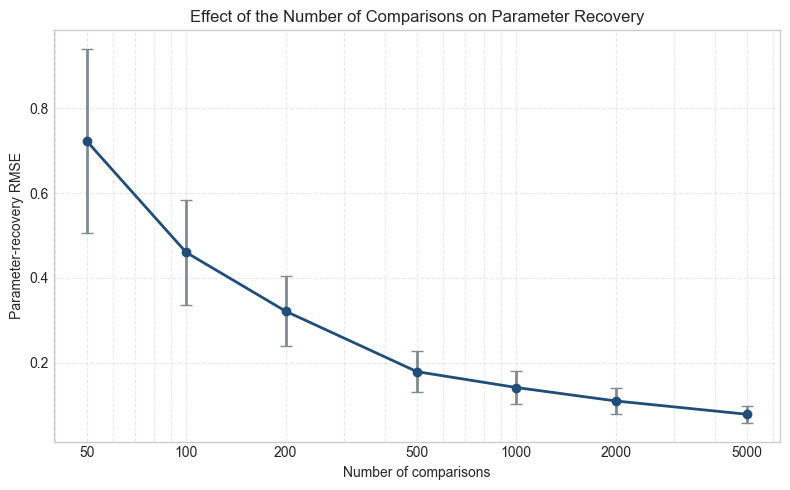

In [36]:
# Plot the mean recovery error with one-standard-deviation error bars.

fig,ax=plt.subplots(
    figsize=(8,5)
)

ax.errorbar(
    comparison_results_table["number_of_comparisons"],
    comparison_results_table["mean_recovery_error"],
    yerr=comparison_results_table["standard_deviation"],
    marker="o",
    markersize=6,
    linewidth=2,
    capsize=4,
    color="#1F4E79",
    ecolor="#7F8C8D"
)

ax.set_xscale("log")

ax.set_xticks(comparison_counts)
ax.set_xticklabels(comparison_counts)

ax.set_xlabel("Number of comparisons")
ax.set_ylabel("Parameter-recovery RMSE")
ax.set_title(
    "Effect of the Number of Comparisons on Parameter Recovery"
)

ax.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()

experiment_1_figure_path = (
    figure_directory
    / "recovery_error_vs_comparisons.pdf"
)

fig.savefig(
    experiment_1_figure_path,
    bbox_inches="tight",
)

print("Figure saved to:")
print(experiment_1_figure_path)

plt.show()

In [37]:
print("Number of parameters:", len(true_parameters))
print("Number of runs:", number_of_runs)

display(comparison_results_table)

Number of parameters: 10
Number of runs: 20


,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,50,0.7225,0.2172,1.2710
1,100,0.4600,0.1247,1.6968
2,200,0.3213,0.0819,2.2255
3,500,0.1786,0.0487,4.2882
4,1000,0.1412,0.0388,7.9877
5,2000,0.1095,0.0309,14.6836
6,5000,0.0780,0.0203,34.1005


In [27]:
# Extend the experiment to larger datasets to examine diminishing returns.(maybe statistical convergence)

additional_comparison_counts=np.array([
    10000,
    20000
])

additional_results=[]

for comparison_count in additional_comparison_counts:
    start_time=perf_counter()

    recovery_errors=run_parameter_recovery_trials(
        true_parameters=true_parameters,
        number_of_comparisons=int(comparison_count),
        number_of_runs=number_of_runs,
        seed=SEED+int(comparison_count),
        learning_rate=learning_rate,
        maximum_iterations=maximum_iterations
    )

    elapsed_time=perf_counter()-start_time

    comparison_errors[int(comparison_count)]=recovery_errors

    additional_results.append({
        "number_of_comparisons":int(comparison_count),
        "mean_recovery_error":np.mean(recovery_errors),
        "standard_deviation":np.std(
            recovery_errors,
            ddof=1
        ),
        "runtime_seconds":elapsed_time
    })

    print(
        f"Completed {comparison_count} comparisons "
        f"in {elapsed_time:.2f} seconds"
    )

comparison_results_table=(
    pd.concat(
        [
            comparison_results_table,
            pd.DataFrame(additional_results)
        ],
        ignore_index=True
    )
    .drop_duplicates(
        subset="number_of_comparisons",
        keep="last"
    )
    .sort_values("number_of_comparisons")
    .reset_index(drop=True)
)

comparison_counts=(
    comparison_results_table[
        "number_of_comparisons"
    ].to_numpy()
)

comparison_results_table

Completed 10000 comparisons in 65.52 seconds
Completed 20000 comparisons in 128.60 seconds


,number_of_comparisons,mean_recovery_error,standard_deviation,runtime_seconds
0,50,0.7225,0.2172,1.2754
1,100,0.4600,0.1247,1.5777
2,200,0.3213,0.0819,2.1646
3,500,0.1786,0.0487,4.1473
4,1000,0.1412,0.0388,7.6144
5,2000,0.1095,0.0309,14.3022
6,5000,0.0780,0.0203,32.9472
7,10000,0.0655,0.0160,65.5217
8,20000,0.0592,0.0107,128.6033


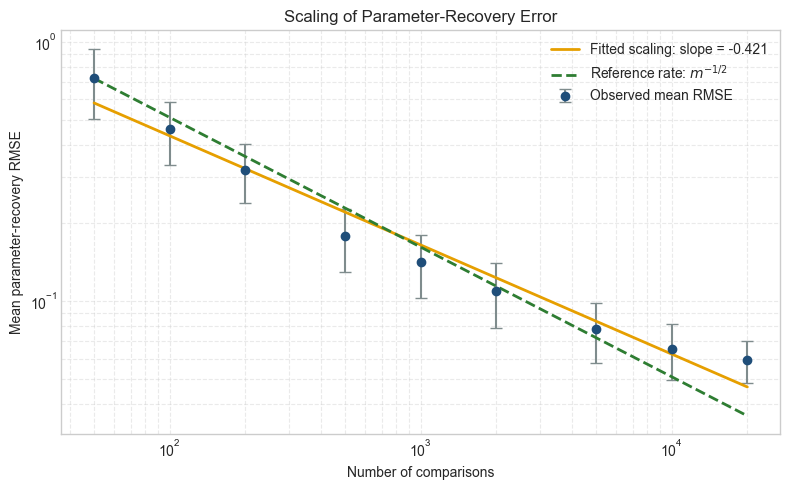

Estimated log-log slope: -0.4208


In [28]:
# Plot the recovery-error scaling and compare it with the theoretical inverse-square-root rate.

comparison_values=(
    comparison_results_table[
        "number_of_comparisons"
    ].to_numpy()
)

mean_errors=(
    comparison_results_table[
        "mean_recovery_error"
    ].to_numpy()
)

error_standard_deviations=(
    comparison_results_table[
        "standard_deviation"
    ].to_numpy()
)

fitted_slope,fitted_intercept=np.polyfit(
    np.log(comparison_values),
    np.log(mean_errors),
    deg=1
)

fitted_errors=np.exp(
    fitted_intercept
)*comparison_values**fitted_slope

inverse_square_root_reference=(
    mean_errors[0]
    *(
        comparison_values/comparison_values[0]
    )**(-0.5)
)

fig,ax=plt.subplots(
    figsize=(8,5)
)

ax.errorbar(
    comparison_values,
    mean_errors,
    yerr=error_standard_deviations,
    fmt="o",
    markersize=6,
    capsize=4,
    color="#1F4E79",
    ecolor="#7F8C8D",
    label="Observed mean RMSE"
)

ax.plot(
    comparison_values,
    fitted_errors,
    linewidth=2,
    color="#E69F00",
    label=f"Fitted scaling: slope = {fitted_slope:.3f}"
)

ax.plot(
    comparison_values,
    inverse_square_root_reference,
    linewidth=2,
    linestyle="--",
    color="#2E7D32",
    label=r"Reference rate: $m^{-1/2}$"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Number of comparisons")
ax.set_ylabel("Mean parameter-recovery RMSE")
ax.set_title("Scaling of Parameter-Recovery Error")

ax.grid(
    True,
    which="both",
    linestyle="--",
    alpha=0.4
)

ax.legend()

plt.tight_layout()
plt.show()

print(f"Estimated log-log slope: {fitted_slope:.4f}")

In [29]:
print("Number of parameters:", len(true_parameters))

Number of parameters: 10


#### Inference of the above graph

Recovery error and its variation decrease as more comparisons are observed. The fitted slope of \(-0.430\) is reasonably close to the theoretical root of 'm' rate(number of comparisons), suggesting approximate inverse-square-root scaling with diminishing returns. This conclusion applies to the current experimental settings and does not establish optimizer convergence.


## Experiment 2: Effect of the Number of Items
Joint Scaling with Items and Comparisons



In [16]:
# Values of n: number of items
item_counts_experiment_2 = np.array([
    10,
    20,
    50,
    100,
    200,
])

# Values of m: number of observed comparisons
comparison_counts_experiment_2 = np.array([
    1_000,
    5_000,
    20_000,
    100_000,
])

experiment_2_settings = []

for number_of_items in item_counts_experiment_2:
    for number_of_comparisons in comparison_counts_experiment_2:

        expected_appearances_per_item = (
            2 * number_of_comparisons / number_of_items
        )

        experiment_2_settings.append({
            "number_of_items": number_of_items,
            "number_of_comparisons": number_of_comparisons,
            "expected_appearances_per_item": expected_appearances_per_item,
        })

experiment_2_settings_table = pd.DataFrame(experiment_2_settings)

experiment_2_settings_table

,number_of_items,number_of_comparisons,expected_appearances_per_item
0,10,1000,200.0
1,10,5000,1000.0
2,10,20000,4000.0
3,10,100000,20000.0
4,20,1000,100.0
5,20,5000,500.0
6,20,20000,2000.0
7,20,100000,10000.0
8,50,1000,40.0
9,50,5000,200.0


In [17]:
# Use the same estimation protocol for every (n, m) setting.

experiment_2_number_of_runs = 5
experiment_2_learning_rate = 0.1
experiment_2_maximum_iterations = 2_000

experiment_2_protocol = pd.DataFrame({
    "setting": [
        "Independent runs per (n, m)",
        "Learning rate",
        "Maximum gradient-descent iterations",
    ],
    "value": [
        experiment_2_number_of_runs,
        experiment_2_learning_rate,
        experiment_2_maximum_iterations,
    ],
})

experiment_2_protocol

,setting,value
0,"Independent runs per (n, m)",5.0
1,Learning rate,0.1
2,Maximum gradient-descent iterations,2000.0


In [18]:
# Run every (n, m) setting manually and store the result of each trial.

experiment_2_run_results = []

for setting_index, setting in enumerate(experiment_2_settings):

    number_of_items = int(setting["number_of_items"])
    number_of_comparisons = int(setting["number_of_comparisons"])

    for run_index in range(experiment_2_number_of_runs):

        run_seed = (
            SEED
            + 10_000
            + setting_index * experiment_2_number_of_runs
            + run_index
        )

        run_rng = np.random.default_rng(run_seed)

        # Generate a new random parameter vector for this trial.
        true_parameters = center_parameters(
            run_rng.normal(
                loc=0.0,
                scale=1.0,
                size=number_of_items,
            )
        )

        run_start_time = perf_counter()

        # Generate observations as (winner, loser) pairs.
        generation_start_time = perf_counter()

        comparisons = generate_uniform_comparison_data(
            true_parameters,
            number_of_comparisons,
            run_rng,
        )

        generation_time = (
            perf_counter() - generation_start_time
        )

        # Count how often every item appeared in the dataset.
        comparison_array = np.asarray(
            comparisons,
            dtype=int,
        )

        appearance_counts = np.bincount(
            comparison_array.ravel(),
            minlength=number_of_items,
        )

        # Estimate the unknown Bradley-Terry parameters.
        estimation_start_time = perf_counter()

        estimated_parameters, nll_history = (
            estimate_parameters_with_gradient_descent(
                number_of_items,
                comparisons,
                learning_rate=experiment_2_learning_rate,
                maximum_iterations=experiment_2_maximum_iterations,
            )
        )

        estimation_time = (
            perf_counter() - estimation_start_time
        )

        recovery_error = parameter_recovery_error(
            true_parameters,
            estimated_parameters,
        )

        total_run_time = (
            perf_counter() - run_start_time
        )

        experiment_2_run_results.append({
            "number_of_items": number_of_items,
            "number_of_comparisons": number_of_comparisons,
            "run": run_index + 1,
            "expected_appearances_per_item": (
                2 * number_of_comparisons / number_of_items
            ),
            "average_appearances_per_item": appearance_counts.mean(),
            "minimum_appearances": appearance_counts.min(),
            "maximum_appearances": appearance_counts.max(),
            "unobserved_items": np.sum(appearance_counts == 0),
            "recovery_error": recovery_error,
            "initial_average_nll": nll_history[0],
            "final_average_nll": nll_history[-1],
            "last_nll_change": abs(
                nll_history[-1] - nll_history[-2]
            ),
            "generation_seconds": generation_time,
            "estimation_seconds": estimation_time,
            "total_seconds": total_run_time,
        })

    print(
        f"Completed: n={number_of_items}, "
        f"m={number_of_comparisons}"
    )

experiment_2_run_results_table = pd.DataFrame(
    experiment_2_run_results
)

experiment_2_run_results_table

Completed: n=10, m=1000
Completed: n=10, m=5000
Completed: n=10, m=20000
Completed: n=10, m=100000
Completed: n=20, m=1000
Completed: n=20, m=5000
Completed: n=20, m=20000
Completed: n=20, m=100000
Completed: n=50, m=1000
Completed: n=50, m=5000
Completed: n=50, m=20000
Completed: n=50, m=100000
Completed: n=100, m=1000
Completed: n=100, m=5000
Completed: n=100, m=20000
Completed: n=100, m=100000
Completed: n=200, m=1000
Completed: n=200, m=5000
Completed: n=200, m=20000
Completed: n=200, m=100000


,number_of_items,number_of_comparisons,run,expected_appearances_per_item,average_appearances_per_item,minimum_appearances,maximum_appearances,unobserved_items,recovery_error,initial_average_nll,final_average_nll,last_nll_change,generation_seconds,estimation_seconds,total_seconds
0,10,1000,1,200.0,200.0,185,215,0,0.1700,0.6931,0.5795,1.1765e-08,0.0013,0.7891,0.7906
1,10,1000,2,200.0,200.0,173,227,0,0.2069,0.6931,0.5922,1.1849e-09,0.0002,0.7428,0.7431
2,10,1000,3,200.0,200.0,176,219,0,0.1409,0.6931,0.5498,8.5776e-09,0.0002,0.7201,0.7204
3,10,1000,4,200.0,200.0,185,217,0,0.1694,0.6931,0.4280,4.8514e-07,0.0002,0.7217,0.7221
4,10,1000,5,200.0,200.0,179,227,0,0.1356,0.6931,0.5552,2.1766e-09,0.0001,0.7405,0.7408
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,200,100000,1,1000.0,1000.0,913,1087,0,0.6914,0.6931,0.6077,2.5565e-05,0.0186,61.6989,61.7308
96,200,100000,2,1000.0,1000.0,930,1079,0,0.6145,0.6931,0.6185,2.2236e-05,0.0146,61.8460,61.8738
97,200,100000,3,1000.0,1000.0,894,1108,0,0.7631,0.6931,0.5992,2.8156e-05,0.0149,61.3264,61.3546
98,200,100000,4,1000.0,1000.0,926,1094,0,0.7072,0.6931,0.6066,2.5915e-05,0.0144,61.9510,61.9786


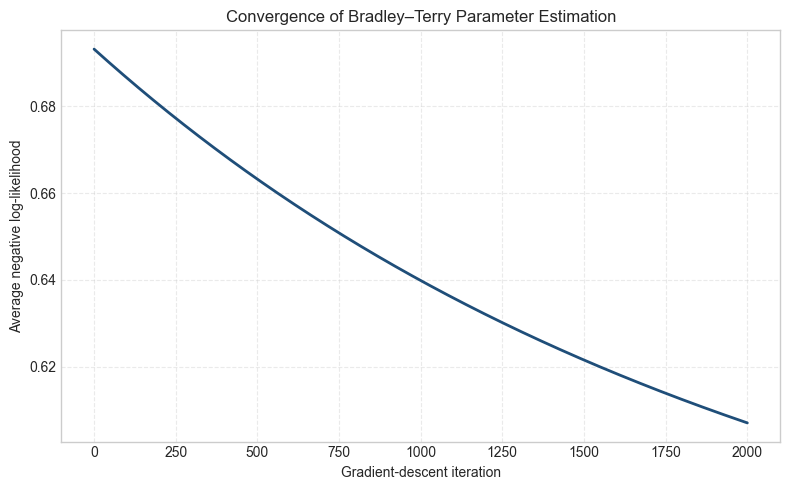

In [19]:
# Plot the optimization history for the baseline experiment.

iteration_indices = np.arange(len(nll_history))

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    iteration_indices,
    nll_history,
    color="#1F4E79",
    linewidth=2,
)

ax.set_xlabel("Gradient-descent iteration")
ax.set_ylabel("Average negative log-likelihood")
ax.set_title("Convergence of Bradley–Terry Parameter Estimation")

ax.grid(
    True,
    linestyle="--",
    alpha=0.4,
)

plt.tight_layout()
plt.show()

In [20]:
experiment_2_run_results_table.head(50)

,number_of_items,number_of_comparisons,run,expected_appearances_per_item,average_appearances_per_item,minimum_appearances,maximum_appearances,unobserved_items,recovery_error,initial_average_nll,final_average_nll,last_nll_change,generation_seconds,estimation_seconds,total_seconds
0,10,1000,1,200.0,200.0,185,215,0,0.1700,0.6931,0.5795,1.1765e-08,0.0013,0.7891,0.7906
1,10,1000,2,200.0,200.0,173,227,0,0.2069,0.6931,0.5922,1.1849e-09,0.0002,0.7428,0.7431
2,10,1000,3,200.0,200.0,176,219,0,0.1409,0.6931,0.5498,8.5776e-09,0.0002,0.7201,0.7204
3,10,1000,4,200.0,200.0,185,217,0,0.1694,0.6931,0.4280,4.8514e-07,0.0002,0.7217,0.7221
4,10,1000,5,200.0,200.0,179,227,0,0.1356,0.6931,0.5552,2.1766e-09,0.0001,0.7405,0.7408
5,10,5000,1,1000.0,1000.0,929,1044,0,0.0725,0.6931,0.5081,3.9216e-08,0.0020,3.2578,3.2606
6,10,5000,2,1000.0,1000.0,967,1026,0,0.0705,0.6931,0.5063,4.8325e-08,0.0006,3.2397,3.2410
7,10,5000,3,1000.0,1000.0,931,1039,0,0.0953,0.6931,0.5127,2.1796e-08,0.0007,3.2181,3.2195
8,10,5000,4,1000.0,1000.0,980,1031,0,0.1126,0.6931,0.4635,7.9714e-08,0.0006,3.2114,3.2127
9,10,5000,5,1000.0,1000.0,957,1083,0,0.0849,0.6931,0.5430,1.5981e-07,0.0006,3.2278,3.2291


In [21]:
# Summarize the repeated runs for every (n, m) setting.

experiment_2_summary = (
    experiment_2_run_results_table
    .groupby(
        ["number_of_items", "number_of_comparisons"],
        as_index=False,
    )
    .agg(
        mean_recovery_error=("recovery_error", "mean"),
        standard_deviation=("recovery_error", "std"),
        mean_minimum_appearances=("minimum_appearances", "mean"),
        mean_unobserved_items=("unobserved_items", "mean"),
        mean_last_nll_change=("last_nll_change", "mean"),
        mean_generation_seconds=("generation_seconds", "mean"),
        mean_estimation_seconds=("estimation_seconds", "mean"),
    )
)

experiment_2_summary

,number_of_items,number_of_comparisons,mean_recovery_error,standard_deviation,mean_minimum_appearances,mean_unobserved_items,mean_last_nll_change,mean_generation_seconds,mean_estimation_seconds
0,10,1000,0.1646,0.0285,179.6,0.0,1.0177e-07,0.0004,0.7428
1,10,5000,0.0872,0.0174,952.8,0.0,6.9773e-08,0.0009,3.2310
2,10,20000,0.0394,0.0092,3891.0,0.0,3.7753e-08,0.0028,12.7268
3,10,100000,0.0184,0.0065,19823.2,0.0,4.7993e-08,0.0128,64.6490
4,20,1000,0.2385,0.0283,81.2,0.0,1.6879e-06,0.0005,0.7724
5,20,5000,0.1241,0.0113,452.0,0.0,1.2941e-06,0.0009,3.4853
6,20,20000,0.1153,0.0790,1915.6,0.0,1.6461e-06,0.0026,12.8367
7,20,100000,0.0994,0.0665,9795.4,0.0,1.5526e-06,0.0114,64.8864
8,50,1000,0.4208,0.0648,25.6,0.0,1.5565e-05,0.0006,0.7179
9,50,5000,0.3228,0.0673,165.4,0.0,1.0967e-05,0.0010,3.2482


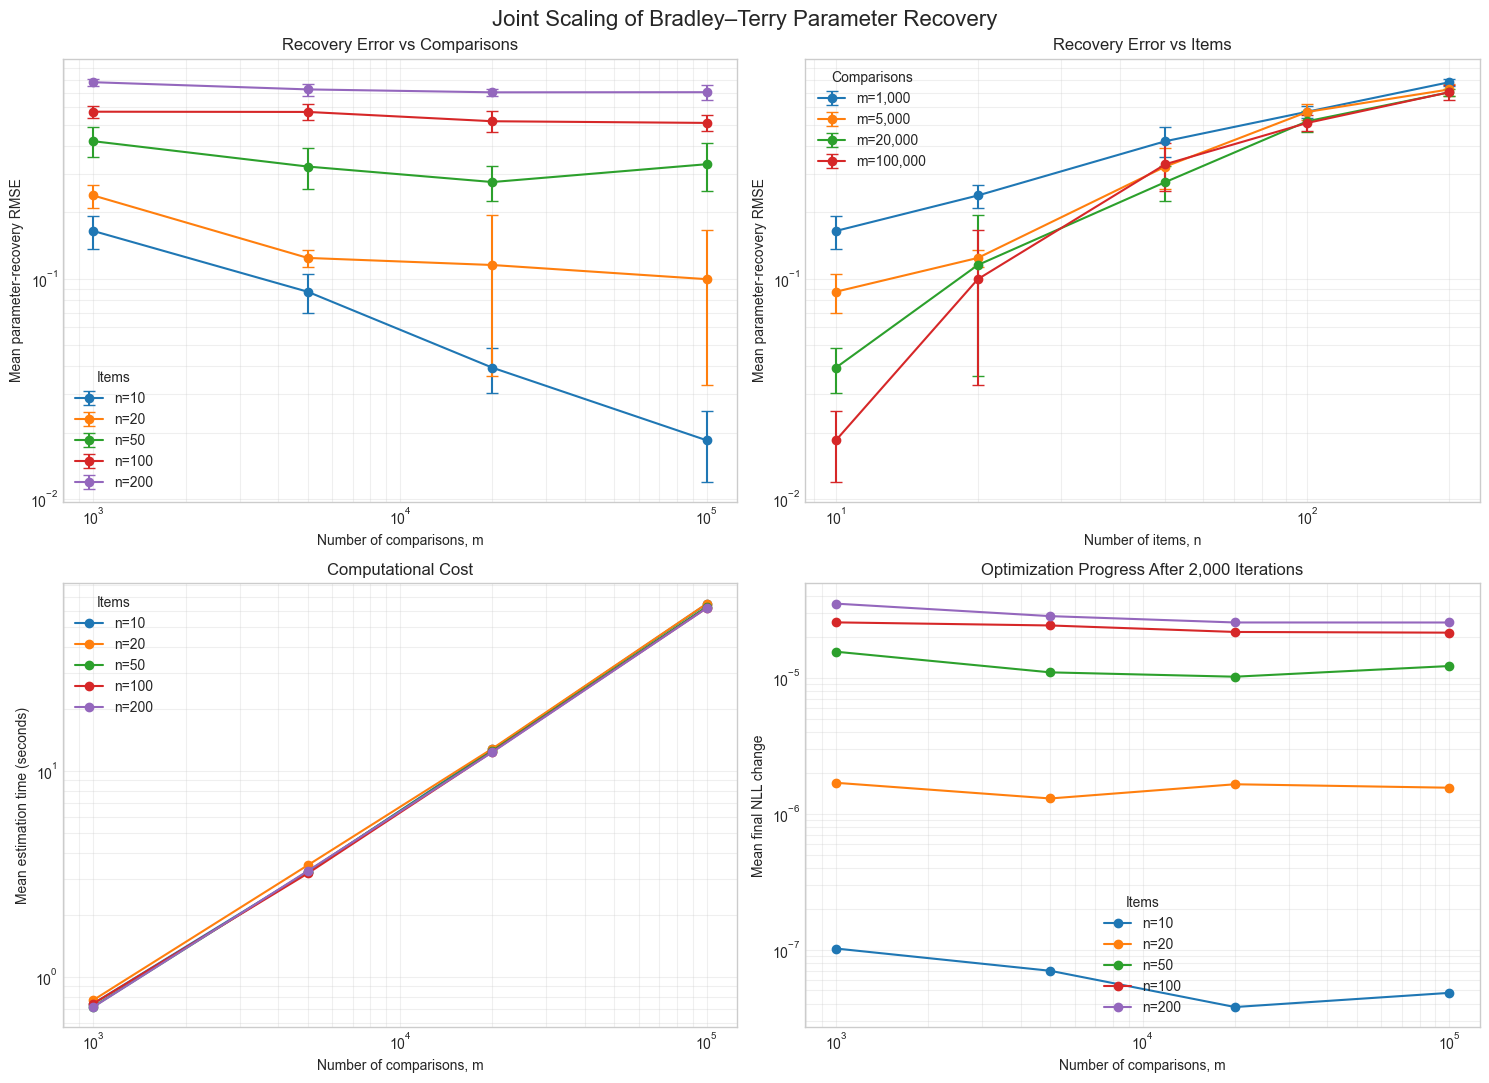

In [22]:
# Visualize statistical accuracy, computational cost and optimization behaviour.

figure, axes = plt.subplots(
    2,
    2,
    figsize=(15, 11),
)

# Plot 1: Recovery error against comparisons
for number_of_items in item_counts_experiment_2:

    subset = experiment_2_summary[
        experiment_2_summary["number_of_items"]
        == number_of_items
    ].sort_values("number_of_comparisons")

    axes[0, 0].errorbar(
        subset["number_of_comparisons"],
        subset["mean_recovery_error"],
        yerr=subset["standard_deviation"],
        marker="o",
        capsize=4,
        label=f"n={number_of_items}",
    )

axes[0, 0].set_xscale("log")
axes[0, 0].set_yscale("log")
axes[0, 0].set_xlabel("Number of comparisons, m")
axes[0, 0].set_ylabel("Mean parameter-recovery RMSE")
axes[0, 0].set_title("Recovery Error vs Comparisons")
axes[0, 0].legend(title="Items")
axes[0, 0].grid(True, which="both", alpha=0.3)


# Plot 2: Recovery error against items
for number_of_comparisons in comparison_counts_experiment_2:

    subset = experiment_2_summary[
        experiment_2_summary["number_of_comparisons"]
        == number_of_comparisons
    ].sort_values("number_of_items")

    axes[0, 1].errorbar(
        subset["number_of_items"],
        subset["mean_recovery_error"],
        yerr=subset["standard_deviation"],
        marker="o",
        capsize=4,
        label=f"m={number_of_comparisons:,}",
    )

axes[0, 1].set_xscale("log")
axes[0, 1].set_yscale("log")
axes[0, 1].set_xlabel("Number of items, n")
axes[0, 1].set_ylabel("Mean parameter-recovery RMSE")
axes[0, 1].set_title("Recovery Error vs Items")
axes[0, 1].legend(title="Comparisons")
axes[0, 1].grid(True, which="both", alpha=0.3)


# Plot 3: Estimation runtime
for number_of_items in item_counts_experiment_2:

    subset = experiment_2_summary[
        experiment_2_summary["number_of_items"]
        == number_of_items
    ].sort_values("number_of_comparisons")

    axes[1, 0].plot(
        subset["number_of_comparisons"],
        subset["mean_estimation_seconds"],
        marker="o",
        label=f"n={number_of_items}",
    )

axes[1, 0].set_xscale("log")
axes[1, 0].set_yscale("log")
axes[1, 0].set_xlabel("Number of comparisons, m")
axes[1, 0].set_ylabel("Mean estimation time (seconds)")
axes[1, 0].set_title("Computational Cost")
axes[1, 0].legend(title="Items")
axes[1, 0].grid(True, which="both", alpha=0.3)


# Plot 4: Final NLL change
for number_of_items in item_counts_experiment_2:

    subset = experiment_2_summary[
        experiment_2_summary["number_of_items"]
        == number_of_items
    ].sort_values("number_of_comparisons")

    nll_changes = np.maximum(
        subset["mean_last_nll_change"],
        1e-12,
    )

    axes[1, 1].plot(
        subset["number_of_comparisons"],
        nll_changes,
        marker="o",
        label=f"n={number_of_items}",
    )

axes[1, 1].set_xscale("log")
axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("Number of comparisons, m")
axes[1, 1].set_ylabel("Mean final NLL change")
axes[1, 1].set_title("Optimization Progress After 2,000 Iterations")
axes[1, 1].legend(title="Items")
axes[1, 1].grid(True, which="both", alpha=0.3)


figure.suptitle(
    "Joint Scaling of Bradley–Terry Parameter Recovery",
    fontsize=16,
)

plt.tight_layout()
plt.show()

#### Interpretation of the plots above

Plot 1(Top-Leftmost): Increasing the comparisons improves recovery clearly for smaller item sets, especially for \(n=10\). However, for larger item sets, the recovery error remains high and changes only slightly as more comparisons are added (purple line, n=200).

Plot 2(Top-Rightmost):The runtime curves almost overlap across different values of \(n\), indicating that the current implementation is mainly affected by the number of comparisons processed during each iteration.

Plot 4(Down leftmost): The final NLL change is also larger for larger item sets. Therefore, the nearly flat recovery-error curves for \(n=50,100,\) and \(200\) should not be interpreted as statistical convergence. They suggest that 2,000 gradient-descent iterations are insufficient for the larger parameter spaces.
